# Rotation vs. Translation in COLMAP and 3D Gaussian Splatting on TUM RGB-D

**Data:** public TUM RGB-D sequences `freiburg1_rpy` (camera rotated at a fixed position) and `freiburg1_xyz` (camera translated, orientation mostly fixed), both a Kinect pointed at an office desk, with motion-capture ground truth.
Cite: J. Sturm, N. Engelhard, F. Endres, W. Burgard, D. Cremers, *A Benchmark for the Evaluation of RGB-D SLAM Systems*, IROS 2012. In any write-up, say you used public TUM RGB-D data; do not describe it as your own capture.

**Questions**
1. How well does a *rotation-only* model (one homography, `R = K^-1 H K`) explain frame pairs from each sequence, measured against ground-truth rotation?
2. How many frames does COLMAP register on each, and how accurate are its relative rotations against ground truth?
3. How well does 3D Gaussian Splatting train on each (PSNR/SSIM/LPIPS from `ns-eval`)?


# Step 0: Install

In [ ]:
!sudo apt-get update -qq && sudo apt-get install -y colmap ffmpeg xvfb
!pip install torch torchvision --index-url https://download.pytorch.org/whl/cu121
!pip install ninja nerfstudio opencv-python matplotlib pandas 

Sudo is disabled on this machine. To enable it, go to the ]8;;ms-settings:developers\Developer Settings page]8;;\ in the Settings app


Looking in indexes: https://download.pytorch.org/whl/cu121


ERROR: Could not find a version that satisfies the requirement torch (from versions: none)

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\Best Hp\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for torch


  Using cached ninja-1.13.2-py3-none-win_amd64.whl.metadata (5.4 kB)
  Using cached nerfstudio-1.1.5-py3-none-any.whl.metadata (24 kB)
  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
  Using cached appdirs-1.4.4-py2.py3-none-any.whl.metadata (9.0 kB)
  Using cached av-19.0.2-cp312-abi3-win_amd64.whl.metadata (5.1 kB)
  Using cached comet_ml-3.58.10-py3-none-any.whl.metadata (4.0 kB)
  Using cached cryptography-50.0.2-cp311-abi3-win_amd64.whl.metadata (4.4 kB)
  Using cached tyro-1.0.17-py3-none-any.whl.metadata (12 kB)
  Using cached gdown-6.5.1-py3-none-any.whl.metadata (11 kB)
  Using cached h5py-3.16.0-cp314-cp314-win_amd64.whl.metadata (3.1 kB)
  Using cached imageio-2.38.1-py3-none-any.whl.metadata (9.7 kB)
  Using cached jaxtyping-0.3.11-py3-none-any.whl.metadata (6.2 kB)
  Using cached mediapy-1.2.7-py3-none-any.whl.metadata (4.8 kB)
  Using cached msgpack-1.2.4-cp314-cp314-win_amd64.whl.metadata (8.5 kB)
  Using cached msgpack_numpy-0.4.8-py2.py3-

  error: subprocess-exited-with-error
  
  × Building wheel for fpsample (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [18 lines of output]
      *** scikit-build-core 1.1.2 using CMake 4.4.4 (wheel)
      *** Configuring CMake...
      loading initial cache file C:\Users\BESTHP~1\AppData\Local\Temp\tmpv_wlpngd\build\CMakeInit.txt
      -- Building for: NMake Makefiles
      CMake Error at CMakeLists.txt:8 (project):
        Running
      
         'nmake' '-?'
      
        failed with:
      
         no such file or directory
      
      
      CMake Error: CMAKE_CXX_COMPILER not set, after EnableLanguage
      -- Configuring incomplete, errors occurred!
      
      *** CMake configuration failed
      [end of output]
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for fpsample
  error: subprocess-exited-with-error
  
  × Building wheel for xatlas (pyproject.toml) did not run successfully

# Step 1: Download the two sequences

If the download fails (the URLs below follow TUM's usual pattern but are not guaranteed), download `fr1/xyz` and `fr1/rpy` as `.tgz` from the TUM RGB-D dataset download page, upload them into a folder named `tum/`, and re-run.

In [ ]:
import os, subprocess, tarfile

SEQS = {"rpy": "rgbd_dataset_freiburg1_rpy", "xyz": "rgbd_dataset_freiburg1_xyz"}
BASES = ["https://cvg.cit.tum.de/rgbd/dataset/freiburg1/", "https://vision.in.tum.de/rgbd/dataset/freiburg1/"]
os.makedirs("tum", exist_ok=True)

for name, folder in SEQS.items():
    if os.path.isdir(f"tum/{folder}"):
        continue
    tgz = f"tum/{folder}.tgz"
    ok = os.path.exists(tgz) and os.path.getsize(tgz) > 1e6
    for base in BASES:
        if ok: break
        r = subprocess.run(["wget", "-q", "-O", tgz, base + folder + ".tgz"])
        ok = r.returncode == 0 and os.path.getsize(tgz) > 1e6
    if not ok:
        raise RuntimeError(f"Could not download {folder}. Download it manually from the TUM page and put {tgz} here.")
    with tarfile.open(tgz) as t:
        t.extractall("tum")
print({n: os.path.isdir(f"tum/{f}") for n, f in SEQS.items()})

/tmp/ipykernel_3532/1651741420.py:19: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  t.extractall("tum")
/tmp/ipykernel_3532/1651741420.py:19: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  t.extractall("tum")


{'rpy': True, 'xyz': True}


# Step 2: Configuration

In [ ]:
import numpy as np
os.environ["MAX_JOBS"] = "1"

# Freiburg 1 RGB intrinsics from the TUM dataset page (OpenCV order: k1 k2 p1 p2 k3)
K = np.array([[517.3, 0, 318.6], [0, 516.5, 255.3], [0, 0, 1.0]])
DIST = np.array([0.2624, -0.9531, -0.0054, 0.0026, 1.1633])

STEPS = [1, 5, 15]      # frame gaps for the pairwise rotation test
NUM_FRAMES = 200        # frames per sequence passed to COLMAP / 3DGS
MIN_REGISTERED = 20     # below this, treat as a COLMAP failure and skip 3DGS
ITERS = 7000

# Step 3: Helper functions

In [ ]:
import cv2, glob, json, os, re, subprocess
import numpy as np

# ---------- TUM RGB-D file readers ----------
def read_rgb_list(path):
    rows = [l.split() for l in open(path) if l.strip() and not l.startswith('#')]
    return [(float(r[0]), r[1]) for r in rows]

def read_groundtruth(path):
    rows = [list(map(float, l.split())) for l in open(path) if l.strip() and not l.startswith('#')]
    return np.array(rows)          # t tx ty tz qx qy qz qw

def quat_to_R(qx, qy, qz, qw):
    n = np.sqrt(qx*qx + qy*qy + qz*qz + qw*qw)
    qx, qy, qz, qw = qx/n, qy/n, qz/n, qw/n
    return np.array([[1-2*(qy*qy+qz*qz), 2*(qx*qy-qz*qw),   2*(qx*qz+qy*qw)],
                     [2*(qx*qy+qz*qw),   1-2*(qx*qx+qz*qz), 2*(qy*qz-qx*qw)],
                     [2*(qx*qz-qy*qw),   2*(qy*qz+qx*qw),   1-2*(qx*qx+qy*qy)]])

def rot_angle_deg(R):
    return float(np.degrees(np.arccos(np.clip((np.trace(R) - 1) / 2, -1, 1))))

def load_sequence(root, max_dt=0.02):
    """Associate each RGB frame with the nearest ground-truth pose."""
    rgb = read_rgb_list(f"{root}/rgb.txt")
    gt = read_groundtruth(f"{root}/groundtruth.txt")
    frames = []
    for t, rel in rgb:
        i = int(np.argmin(np.abs(gt[:, 0] - t)))
        if abs(gt[i, 0] - t) <= max_dt:
            frames.append(dict(t=t, path=f"{root}/{rel}",
                               Rq=quat_to_R(*gt[i, 4:8]), p=gt[i, 1:4].copy()))
    return frames

def gt_stats(frames):
    P = np.array([f['p'] for f in frames])
    path_len = float(np.linalg.norm(np.diff(P, axis=0), axis=1).sum())
    extent = (P.max(0) - P.min(0)).tolist()
    R0 = frames[0]['Rq']
    max_rot = max(rot_angle_deg(R0.T @ f['Rq']) for f in frames)
    return dict(n_frames=len(frames), gt_path_m=path_len, gt_extent_m=extent, gt_max_rot_from_start_deg=max_rot)

# ---------- undistortion ----------
def undistort_all(frames, out_dir, K, DIST, size=(640, 480)):
    os.makedirs(out_dir, exist_ok=True)
    newK, _ = cv2.getOptimalNewCameraMatrix(K, DIST, size, 0)
    m1, m2 = cv2.initUndistortRectifyMap(K, DIST, None, newK, size, cv2.CV_32FC1)
    for i, f in enumerate(frames):
        img = cv2.imread(f['path'])
        out = f"{out_dir}/{i:05d}.png"
        cv2.imwrite(out, cv2.remap(img, m1, m2, cv2.INTER_LINEAR))
        f['und'] = out
    return newK

# ---------- homography rotation vs ground truth ----------
def sift_features(frames):
    sift = cv2.SIFT_create()
    return [sift.detectAndCompute(cv2.imread(f['und'], cv2.IMREAD_GRAYSCALE), None) for f in frames]

def gt_rel(frames, i, j, conv):
    Ri, Rj = frames[i]['Rq'], frames[j]['Rq']
    return Rj.T @ Ri if conv == "A" else Rj @ Ri.T

def rotation_vs_gt(frames, feats, K, step, conv, stride=3):
    """Per-pair rotation from a single homography (R = K^-1 H K) compared with ground truth."""
    bf, Kinv = cv2.BFMatcher(), np.linalg.inv(K)
    rows, failed = [], 0
    for i in range(0, len(frames) - step, stride):
        j = i + step
        (kp1, d1), (kp2, d2) = feats[i], feats[j]
        if d1 is None or d2 is None or len(kp1) < 10 or len(kp2) < 10:
            failed += 1; continue
        good = [m for m, n in (p for p in bf.knnMatch(d1, d2, k=2) if len(p) == 2) if m.distance < 0.75 * n.distance]
        if len(good) < 30:
            failed += 1; continue
        p1 = np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
        p2 = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
        H, inl = cv2.findHomography(p1, p2, cv2.RANSAC, 3.0)
        if H is None:
            failed += 1; continue
        err = np.linalg.norm(cv2.perspectiveTransform(p1, H) - p2, axis=2).ravel()
        Hn = Kinv @ H @ K
        Hn /= np.cbrt(np.linalg.det(Hn))
        U, _, Vt = np.linalg.svd(Hn)
        R = U @ Vt
        if np.linalg.det(R) < 0:
            R = -R
        Rg = gt_rel(frames, i, j, conv)
        rows.append(dict(i=i, step=step, n_matches=len(good), inlier_ratio=float(inl.mean()),
                         median_err_px=float(np.median(err)),
                         rot_err_deg=rot_angle_deg(R.T @ Rg), gt_rot_deg=rot_angle_deg(Rg),
                         gt_trans_m=float(np.linalg.norm(frames[j]['p'] - frames[i]['p']))))
    return rows, failed

def detect_convention(frames, feats, K, step=5):
    """Ground-truth quaternions may be cam-to-world (A) or world-to-cam (B); pick the one that agrees with the images."""
    out = {}
    for conv in ("A", "B"):
        rows, _ = rotation_vs_gt(frames, feats, K, step, conv, stride=5)
        out[conv] = float(np.median([r['rot_err_deg'] for r in rows])) if rows else float('inf')
    best = min(out, key=out.get)
    return best, out

# ---------- COLMAP ----------
def colmap_stats(sparse_dir):
    p = subprocess.run(["colmap", "model_analyzer", "--path", sparse_dir], capture_output=True, text=True)
    out = p.stdout + p.stderr
    def grab(pat):
        m = re.search(pat, out)
        return float(m.group(1)) if m else None
    return dict(registered=grab(r"Registered images:\s*(\d+)"), points3D=grab(r"Points:\s*(\d+)"),
                track_len=grab(r"Mean track length:\s*([\d.]+)"), reproj_px=grab(r"Mean reprojection error:\s*([\d.]+)"))

def colmap_rotation_error(sparse_dir, sub_frames, conv, step=10):
    """Relative rotations between registered images (COLMAP) vs ground truth. Gauge-free, no alignment needed."""
    txt = sparse_dir + "_txt"
    os.makedirs(txt, exist_ok=True)
    subprocess.run(["colmap", "model_converter", "--input_path", sparse_dir, "--output_path", txt,
                    "--output_type", "TXT"], capture_output=True)
    lines = [l for l in open(f"{txt}/images.txt") if l.strip() and not l.startswith('#')]
    poses = {}
    for l in lines[::2]:
        p = l.split()
        qw, qx, qy, qz = map(float, p[1:5])
        k = int(re.findall(r"(\d+)", os.path.basename(p[9]))[-1]) - 1
        poses[k] = quat_to_R(qx, qy, qz, qw)          # COLMAP: world -> camera
    errs = []
    for a in sorted(poses):
        b = a + step
        if b in poses and b < len(sub_frames):
            R_est = poses[b] @ poses[a].T
            R_gt = gt_rel(sub_frames, a, b, conv)
            errs.append(rot_angle_deg(R_est.T @ R_gt))
    return errs

# Step 4: Load sequences, ground-truth statistics, undistort

The statistics printed here tell you what each sequence really contains. Both are described as mostly one kind of motion, not purely one kind, so state the measured amounts in any write-up.

In [ ]:
RESULTS = {n: {} for n in SEQS}
SEQ = {}
for name, folder in SEQS.items():
    frames = load_sequence(f"tum/{folder}")
    newK = undistort_all(frames, f"work/{name}_und", K, DIST)
    SEQ[name] = dict(frames=frames, newK=newK)
    s = gt_stats(frames)
    RESULTS[name].update(s)
    print(name, {k: (np.round(v, 3).tolist() if not isinstance(v, int) else v) for k, v in s.items()})

rpy {'n_frames': 720, 'gt_path_m': 2.225, 'gt_extent_m': [0.147, 0.18, 0.19], 'gt_max_rot_from_start_deg': 112.741}
xyz {'n_frames': 796, 'gt_path_m': 8.011, 'gt_extent_m': [0.457, 0.697, 0.398], 'gt_max_rot_from_start_deg': 22.159}


# Step 5: Rotation-only model vs. ground truth

For each frame pair, one homography is estimated and converted to a rotation. Its angular error against the motion-capture rotation is reported, plus how well one homography explains the image (inlier ratio, residual). If rotation-only modelling works for `rpy` and degrades for `xyz`, that is the measurable effect of translation.

The code first checks whether the ground-truth quaternions behave as camera-to-world or world-to-camera by seeing which agrees with the images on the `rpy` sequence.

Ground-truth convention: A | median rotation error under each convention (deg): {'A': 0.6179603380324497, 'B': 11.979390492911005}
          gt_rot_deg  gt_trans_m  rot_err_deg  inlier_ratio  median_err_px
seq step                                                                  
rpy 1          1.989       0.003        0.337         0.863          0.669
    5         10.151       0.015        0.659         0.785          1.109
    15        28.919       0.041        1.556         0.624          1.699
xyz 1          0.525       0.011        0.342         0.914          0.480
    5          2.173       0.055        1.484         0.788          0.952
    15         4.888       0.154        4.161         0.638          1.498


/tmp/ipykernel_3532/3059088177.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  a.boxplot([d[d.seq == n].rot_err_deg for n in SEQ], labels=list(SEQ))
/tmp/ipykernel_3532/3059088177.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  a.boxplot([d[d.seq == n].rot_err_deg for n in SEQ], labels=list(SEQ))
/tmp/ipykernel_3532/3059088177.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  a.boxplot([d[d.seq == n].rot_err_deg for n in SEQ], labels=list(SEQ))


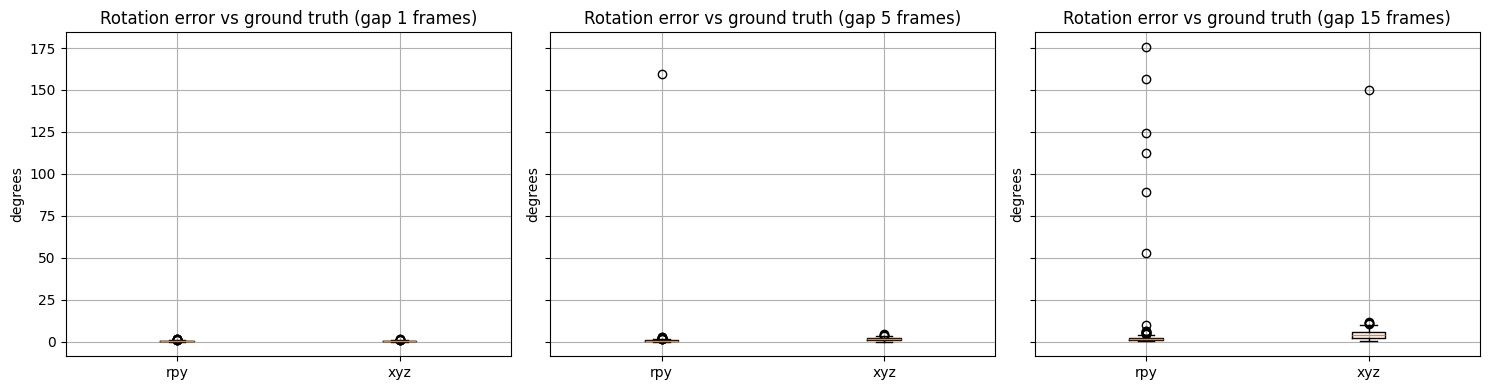

In [ ]:
import pandas as pd, matplotlib.pyplot as plt

for name in SEQ:
    SEQ[name]["feats"] = sift_features(SEQ[name]["frames"])
newK = SEQ["rpy"]["newK"]

conv, diag = detect_convention(SEQ["rpy"]["frames"], SEQ["rpy"]["feats"], newK)
print("Ground-truth convention:", conv, "| median rotation error under each convention (deg):", diag)
if min(diag.values()) > 10:
    print("WARNING: both conventions disagree strongly with the images. The ground truth may be in a different frame; check the TUM file-format page before trusting the numbers below.")

tables = []
for name in SEQ:
    for step in STEPS:
        rows, failed = rotation_vs_gt(SEQ[name]["frames"], SEQ[name]["feats"], newK, step, conv)
        df = pd.DataFrame(rows); df["seq"] = name; tables.append(df)
        RESULTS[name][f"rot_err_median_deg_step{step}"] = float(df.rot_err_deg.median())
        RESULTS[name][f"rot_err_p90_deg_step{step}"] = float(df.rot_err_deg.quantile(0.9))
        RESULTS[name][f"gt_rot_median_deg_step{step}"] = float(df.gt_rot_deg.median())
        RESULTS[name][f"inlier_ratio_step{step}"] = float(df.inlier_ratio.mean())
        RESULTS[name][f"failed_pairs_step{step}"] = int(failed)
all_pairs = pd.concat(tables)
print(all_pairs.groupby(["seq", "step"])[["gt_rot_deg", "gt_trans_m", "rot_err_deg", "inlier_ratio", "median_err_px"]].median().round(3))

fig, ax = plt.subplots(1, len(STEPS), figsize=(5 * len(STEPS), 4), sharey=True)
for a, step in zip(np.atleast_1d(ax), STEPS):
    d = all_pairs[all_pairs.step == step]
    a.boxplot([d[d.seq == n].rot_err_deg for n in SEQ], labels=list(SEQ))
    a.set_title(f"Rotation error vs ground truth (gap {step} frames)"); a.set_ylabel("degrees"); a.grid(True)
plt.tight_layout(); plt.savefig("rotation_error_vs_gt.png", dpi=200); plt.show()

# Step 6: COLMAP on both sequences

`ns-process-data images` runs COLMAP. Frames are saved as `00000.png, 00001.png, ...` so that COLMAP's output can be mapped back to ground truth. If COLMAP fails or registers few frames on a sequence, report that as the finding.

In [ ]:
import glob, shutil

for name in SEQ:
    frames = SEQ[name]["frames"]
    idx = np.linspace(0, len(frames) - 1, NUM_FRAMES).astype(int)
    sub = [frames[k] for k in idx]
    SEQ[name]["sub"] = sub
    in_dir = f"work/{name}_colmap_in"
    shutil.rmtree(in_dir, ignore_errors=True); os.makedirs(in_dir)
    for k, f in enumerate(sub):
        shutil.copy(f["und"], f"{in_dir}/{k:05d}.png")
    out = f"data/{name}"
    p = subprocess.run(["xvfb-run", "-a", "ns-process-data", "images", "--data", in_dir, "--output-dir", out,
                        "--matching-method", "sequential"], capture_output=True, text=True)
    sparse = f"{out}/colmap/sparse/0"
    stats = colmap_stats(sparse) if os.path.isdir(sparse) else dict(registered=0, points3D=0, track_len=None, reproj_px=None)
    stats["input_frames"] = len(sub)
    stats["registration_rate"] = (stats["registered"] or 0) / len(sub)
    if os.path.isdir(sparse) and (stats["registered"] or 0) >= 2:
        errs = colmap_rotation_error(sparse, sub, conv, step=10)
        if errs:
            stats["colmap_rot_err_median_deg"] = float(np.median(errs))
            stats["colmap_rot_err_p90_deg"] = float(np.percentile(errs, 90))
            stats["colmap_rot_pairs"] = len(errs)
    RESULTS[name].update(stats)
    print(name, "exit", p.returncode, stats)
    if p.returncode != 0:
        print((p.stdout + p.stderr)[-1500:])

rpy exit 0 {'registered': 4.0, 'points3D': 2.0, 'track_len': 2.0, 'reproj_px': 0.0, 'input_frames': 200, 'registration_rate': 0.02}
xyz exit 0 {'registered': 200.0, 'points3D': 17819.0, 'track_len': 14.270498, 'reproj_px': 0.806312, 'input_frames': 200, 'registration_rate': 1.0, 'colmap_rot_err_median_deg': 0.9972943201560199, 'colmap_rot_err_p90_deg': 2.081710306754778, 'colmap_rot_pairs': 190}


# Step 7: Train and evaluate 3D Gaussian Splatting

In [2]:
def train_eval(name, tag="unmasked"):
    exp = f"{name}_{tag}"
    get_ipython().system(f"ns-train splatfacto --data data/{name} --max-num-iterations {ITERS} "
                         f"--experiment-name {exp} --vis tensorboard")
    cfgs = sorted(glob.glob(f"outputs/{exp}/splatfacto/*/config.yml"))
    if not cfgs:
        print("Training did not produce a config for", exp); return None
    os.makedirs("results", exist_ok=True)
    out_json = f"results/{exp}.json"
    get_ipython().system(f"ns-eval --load-config {cfgs[-1]} --output-path {out_json}")
    res = json.load(open(out_json))["results"]
    return {f"3dgs_{k}": res.get(k) for k in ("psnr", "ssim", "lpips")}

trainable = [n for n in SEQ if (RESULTS[n].get("registered") or 0) >= MIN_REGISTERED]
print("Trainable:", trainable, "| skipped:", [n for n in SEQ if n not in trainable])
for name in trainable:
    r = train_eval(name)
    if r: RESULTS[name].update(r)

Trainable: ['xyz'] | skipped: ['rpy']
/bin/bash: line 1: ns-train: command not found
Training did not produce a config for xyz_unmasked


# Step 8: Summary

In [ ]:
import pandas as pd
import os

# Create results directory if it doesn't exist
os.makedirs("results", exist_ok=True)

# Safely load results to DataFrame
summary = pd.DataFrame(RESULTS).T
summary.to_csv("results_summary.csv")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

print("Current Results Summary:")
display(summary.T)

Current Results Summary:


,rpy,xyz
n_frames,720,796
gt_path_m,2.224927,8.010684
gt_extent_m,"[0.1469999999999998, 0.1805, 0.18989999999999996]","[0.45650000000000013, 0.6974, 0.39769999999999..."
gt_max_rot_from_start_deg,112.741055,22.158744
rot_err_median_deg_step1,0.336914,0.342085
rot_err_p90_deg_step1,0.704236,0.636496
gt_rot_median_deg_step1,1.989037,0.52536
inlier_ratio_step1,0.843661,0.893347
failed_pairs_step1,1,0
rot_err_median_deg_step5,0.658959,1.484338
